# A2 · Análisis de Rentabilidad y Comportamiento de Compra
**Proyecto 01 — Retail Intelligence (RetailVenture C.A.)**

Preguntas del enunciado:
1. ¿Qué **segmentos, categorías y canales** aportan más y menos al margen bruto total?
2. ¿Cuál es el **CLV estimado por segmento** y qué segmentos están **en declive**?
3. ¿Hay **estacionalidad**? Picos, valles y tendencias por categoría y canal.
4. ¿Los **descuentos** generan suficiente volumen para compensar el margen que sacrifican?

Datos de entrada: tablas limpias de `data/clean/`, generadas en A1.

**Definiciones de margen** (todas en USD):
- `margen_bruto` = monto_neto − costo_total (después de descuento, antes de devoluciones).
- `margen_neto` (escenario base) = margen_bruto − monto_devuelto + costo recuperado. El producto devuelto vuelve al inventario, salvo que el motivo sea *defectuoso* o *fraude*.
- `margen_neto_pesimista` = margen_bruto − monto_devuelto, es decir, no se recupera ningún producto. Se usa como sensibilidad.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
import statsmodels.api as sm, statsmodels.formula.api as smf
from scipy import stats
from pathlib import Path

pd.set_option('display.max_columns', 40); pd.set_option('display.width', 170)
CLEAN, FIG, TAB = Path('../data/clean'), Path('../outputs/figuras'), Path('../outputs/tablas')

ventas = pd.read_csv(CLEAN / 'fact_ventas.csv', parse_dates=['fecha'])
clientes = pd.read_csv(CLEAN / 'dim_cliente.csv', parse_dates=['fecha_registro', 'primera_compra', 'ultima_compra', 'fecha_alta_efectiva'])
ventas = ventas.merge(clientes[['cliente_id', 'segmento', 'ciudad', 'rango_edad', 'canal_adquisicion']], on='cliente_id', how='left')
ventas['anio'] = ventas.fecha.dt.year
ventas['mes'] = ventas.fecha.dt.to_period('M')

PALETA = {'Premium': '#2E4057', 'Frecuente': '#4C72B0', 'Esporádico': '#8DA0CB', 'Nuevo': '#55A868', 'Inactivo': '#C44E52'}
ORDEN_SEG = ['Premium', 'Frecuente', 'Esporádico', 'Nuevo', 'Inactivo']
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.titleweight': 'bold', 'axes.titlesize': 12})
usd = mtick.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M' if abs(x) >= 1e6 else f'${x/1e3:.0f}K')

tot = ventas[['monto_neto', 'margen_bruto', 'margen_neto', 'descuento_monto', 'monto_devuelto']].sum()
print(f"Ventas netas: ${tot.monto_neto:,.0f} | Margen bruto: ${tot.margen_bruto:,.0f} ({tot.margen_bruto/tot.monto_neto:.1%}) | "
      f"Margen neto: ${tot.margen_neto:,.0f} ({tot.margen_neto/tot.monto_neto:.1%})")
print(f"Descuentos concedidos: ${tot.descuento_monto:,.0f} | Devuelto: ${tot.monto_devuelto:,.0f}")

Ventas netas: $17,392,987 | Margen bruto: $4,310,329 (24.8%) | Margen neto: $3,123,230 (18.0%)
Descuentos concedidos: $967,701 | Devuelto: $2,534,466


## 1. Contribución al margen por segmento, categoría y canal

In [2]:
def contribucion(by, df=ventas):
    g = df.groupby(by).agg(transacciones=('transaccion_id', 'size'), clientes=('cliente_id', 'nunique'),
                           ventas=('monto_neto', 'sum'), descuentos=('descuento_monto', 'sum'), margen_bruto=('margen_bruto', 'sum'),
                           devuelto=('monto_devuelto', 'sum'), margen_neto=('margen_neto', 'sum'),
                           margen_neto_pes=('margen_neto_pesimista', 'sum'), desc_prom=('descuento', 'mean'), tasa_dev=('flag_devuelta', 'mean'))
    g['%_ventas'] = g.ventas / g.ventas.sum() * 100
    g['%_margen_bruto'] = g.margen_bruto / g.margen_bruto.sum() * 100
    g['%_margen_neto'] = g.margen_neto / g.margen_neto.sum() * 100
    g['mb_%'] = g.margen_bruto / g.ventas * 100
    g['mn_%'] = g.margen_neto / g.ventas * 100
    g['mn_pes_%'] = g.margen_neto_pes / g.ventas * 100
    g['indice_margen'] = g['%_margen_bruto'] / g['%_ventas']     # >1: aporta más margen que ventas
    g['desc_prom'] *= 100; g['tasa_dev'] *= 100
    return g.sort_values('margen_bruto', ascending=False)

cols = ['ventas', 'margen_bruto', 'margen_neto', '%_ventas', '%_margen_bruto', '%_margen_neto', 'mb_%', 'mn_%', 'mn_pes_%', 'indice_margen', 'desc_prom', 'tasa_dev']
fmt = {c: '{:,.0f}' for c in ['ventas', 'margen_bruto', 'margen_neto']} | {c: '{:.1f}' for c in cols[3:]}
res = {}
for dim in ['segmento', 'categoria', 'canal']:
    res[dim] = contribucion(dim); res[dim].to_csv(TAB / f'a2_contribucion_{dim}.csv')
    print(f'\n=== {dim.upper()} ==='); display(res[dim][cols].style.format(fmt).background_gradient(subset=['mn_%'], cmap='RdYlGn'))


=== SEGMENTO ===


,ventas,margen_bruto,margen_neto,%_ventas,%_margen_bruto,%_margen_neto,mb_%,mn_%,mn_pes_%,indice_margen,desc_prom,tasa_dev
segmento,,,,,,,,,,,,
Frecuente,"8,766,759","2,131,971","1,530,616",50.4,49.5,49.0,24.3,17.5,9.5,1.0,5.6,13.5
Premium,"5,280,661","1,345,563","995,062",30.4,31.2,31.9,25.5,18.8,11.6,1.0,4.2,13.4
Esporádico,"2,701,502","674,499","482,895",15.5,15.6,15.5,25.0,17.9,9.8,1.0,5.7,13.7
Nuevo,"326,779","80,590","65,456",1.9,1.9,2.1,24.7,20.0,11.4,1.0,5.5,12.1
Inactivo,"317,287","77,706","49,202",1.8,1.8,1.6,24.5,15.5,7.7,1.0,5.8,12.6



=== CATEGORIA ===


,ventas,margen_bruto,margen_neto,%_ventas,%_margen_bruto,%_margen_neto,mb_%,mn_%,mn_pes_%,indice_margen,desc_prom,tasa_dev
categoria,,,,,,,,,,,,
Hogar_y_Deco,"4,465,865","1,353,038","1,134,557",25.7,31.4,36.3,30.3,25.4,20.9,1.2,5.1,9.8
Electrónica,"7,662,506","1,049,301","486,468",44.1,24.3,15.6,13.7,6.3,-4.6,0.6,5.3,17.7
Deportes,"2,592,709","907,214","757,171",14.9,21.0,24.2,35.0,29.2,24.5,1.4,5.4,10.7
Ropa_y_Calzado,"1,513,397","597,005","410,523",8.7,13.9,13.1,39.4,27.1,18.2,1.6,5.1,21.8
Belleza_y_Salud,"748,632","309,503","261,085",4.3,7.2,8.4,41.3,34.9,30.7,1.7,5.2,10.6
Alimentos_y_Bebidas,"409,879","94,268","73,425",2.4,2.2,2.4,23.0,17.9,12.5,0.9,5.1,10.2



=== CANAL ===


,ventas,margen_bruto,margen_neto,%_ventas,%_margen_bruto,%_margen_neto,mb_%,mn_%,mn_pes_%,indice_margen,desc_prom,tasa_dev
canal,,,,,,,,,,,,
tienda_fisica,"7,862,504","2,046,092","1,503,792",45.2,47.5,48.1,26.0,19.1,11.7,1.1,3.7,13.2
online,"6,547,309","1,491,186","1,066,957",37.6,34.6,34.2,22.8,16.3,8.1,0.9,7.5,13.8
app_movil,"2,983,174","773,052","552,481",17.2,17.9,17.7,25.9,18.5,10.9,1.0,3.7,13.3


**Lectura**

**Segmentos:** Frecuente (50% del margen bruto) y Premium (31%) concentran el **81% del margen**; Nuevo e Inactivo aportan menos del 2% cada uno. El margen *porcentual* es casi igual en todos los segmentos (24,3–25,5%), así que los segmentos se diferencian por **volumen y recurrencia**, no por rentabilidad unitaria. Premium tiene el mejor margen bruto (25,5%) porque recibe el menor descuento promedio (4,2% vs. ~5,6%).

**Categorías:** aquí está la mayor asimetría.
- **Hogar y Deco** es el mayor contribuyente: 31% del margen bruto y **36% del margen neto** con solo el 26% de las ventas.
- **Electrónica** es el 44% de las ventas, pero solo el 24% del margen bruto y el 16% del margen neto. Tiene el margen más bajo (13,7% bruto, 6,3% neto) y una de las tasas de devolución más altas (17,7%).
- **Belleza y Salud** tiene el mejor margen (41% bruto, 35% neto), pero es apenas el 4% de las ventas: es una oportunidad de crecimiento.
- **Alimentos y Bebidas** es la categoría que menos aporta (2,2% del margen).
- **Ropa y Calzado** tiene buen margen bruto (39%), pero la tasa de devolución más alta (21,8%) le quita 12 pp de margen.

**Canales:** la tienda física aporta más margen del que vende (45% de las ventas, 48% del margen). El canal **online** es el de menor rentabilidad: 37,6% de las ventas pero 34,6% del margen bruto (22,8% vs. 26,0% en tienda).

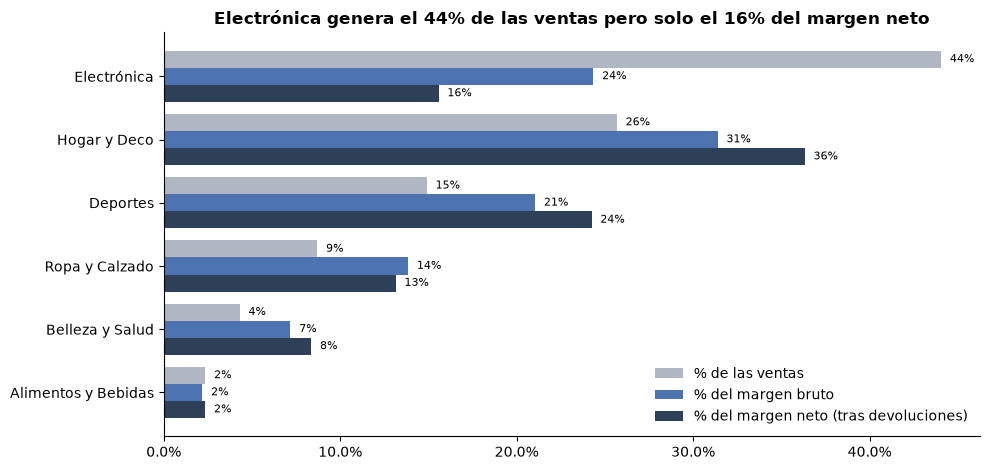

In [3]:
# Visualización clave: participación en ventas vs. margen bruto vs. margen neto, por categoría
c = res['categoria'].sort_values('%_ventas', ascending=True)
fig, ax = plt.subplots(figsize=(10, 4.8)); y = np.arange(len(c)); h = .27
ax.barh(y + h, c['%_ventas'], h, label='% de las ventas', color='#B0B7C3')
ax.barh(y, c['%_margen_bruto'], h, label='% del margen bruto', color='#4C72B0')
ax.barh(y - h, c['%_margen_neto'], h, label='% del margen neto (tras devoluciones)', color='#2E4057')
for i, (v, mb, mn) in enumerate(zip(c['%_ventas'], c['%_margen_bruto'], c['%_margen_neto'])):
    ax.text(v + .5, i + h, f'{v:.0f}%', va='center', fontsize=8); ax.text(mb + .5, i, f'{mb:.0f}%', va='center', fontsize=8)
    ax.text(max(mn, 0) + .5, i - h, f'{mn:.0f}%', va='center', fontsize=8)
ax.set_yticks(y, c.index.str.replace('_', ' ')); ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.legend(loc='lower right', frameon=False)
e = res['categoria'].loc['Electrónica']
ax.set_title(f"Electrónica genera el {e['%_ventas']:.0f}% de las ventas pero solo el {e['%_margen_neto']:.0f}% del margen neto")
plt.tight_layout(); plt.savefig(FIG / 'a2_categoria_ventas_vs_margen.png', dpi=150); plt.show()

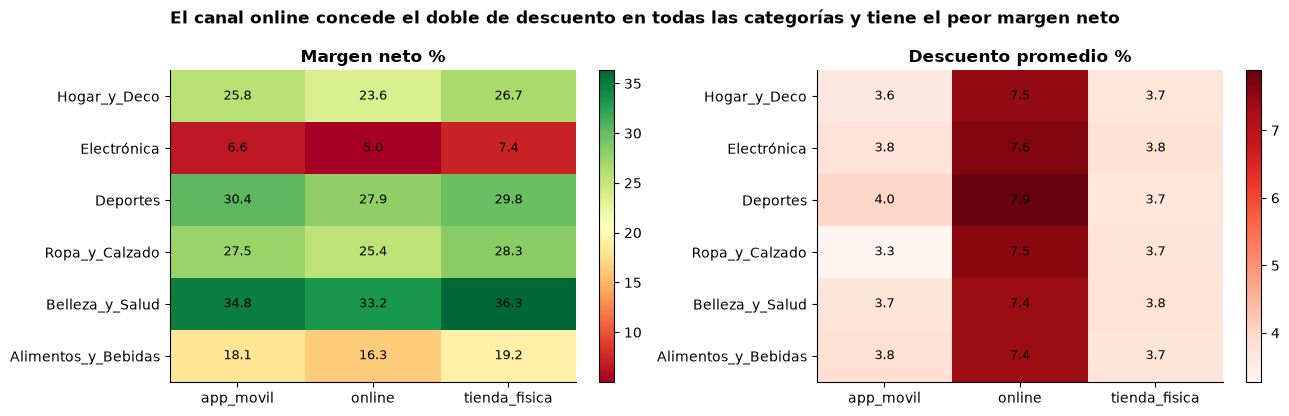

In [4]:
# Mapa categoría × canal: margen neto %
cc = contribucion(['categoria', 'canal'])
piv = cc['mn_%'].unstack().loc[res['categoria'].index]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (m, t) in zip(axes, [('mn_%', 'Margen neto %'), ('desc_prom', 'Descuento promedio %')]):
    p = cc[m].unstack().loc[res['categoria'].index]
    im = ax.imshow(p.values, cmap='RdYlGn' if m == 'mn_%' else 'Reds', aspect='auto')
    ax.set_xticks(range(p.shape[1]), p.columns); ax.set_yticks(range(p.shape[0]), p.index)
    for (r, k), v in np.ndenumerate(p.values): ax.text(k, r, f'{v:.1f}', ha='center', va='center', fontsize=9)
    ax.set_title(t); plt.colorbar(im, ax=ax, fraction=.04)
plt.suptitle('El canal online concede el doble de descuento en todas las categorías y tiene el peor margen neto', fontweight='bold')
plt.tight_layout(); plt.savefig(FIG / 'a2_categoria_canal_heatmap.png', dpi=150); plt.show()
cc.to_csv(TAB / 'a2_contribucion_categoria_canal.csv')

In [5]:
# ¿La brecha de margen del canal online se explica por el descuento? Margen a precio de lista vs. margen real
ch = ventas.groupby('canal').agg(ing_lista=('ingreso_bruto', 'sum'), ventas=('monto_neto', 'sum'), costo=('costo_total', 'sum'), desc=('descuento_monto', 'sum'))
ch['margen_a_precio_lista_%'] = (ch.ing_lista - ch.costo) / ch.ing_lista * 100
ch['margen_real_%'] = (ch.ventas - ch.costo) / ch.ventas * 100
ch['descuento_%_ingreso'] = ch.desc / ch.ing_lista * 100
ch['margen_sacrificado_USD'] = ch.desc
display(ch.round(2))
# Mix de categorías por canal (¿online vende más electrónica?)
display((pd.crosstab(ventas.canal, ventas.categoria, values=ventas.monto_neto, aggfunc='sum', normalize='index') * 100).round(1))

,ing_lista,ventas,costo,desc,margen_a_precio_lista_%,margen_real_%,descuento_%_ingreso,margen_sacrificado_USD
canal,,,,,,,,
app_movil,3103165.11,2983173.98,2210122.07,119991.13,28.78,25.91,3.87,119991.13
online,7090309.73,6547309.24,5056123.74,543000.49,28.69,22.78,7.66,543000.49
tienda_fisica,8167213.84,7862504.26,5816412.62,304709.58,28.78,26.02,3.73,304709.58


categoria,Alimentos_y_Bebidas,Belleza_y_Salud,Deportes,Electrónica,Hogar_y_Deco,Ropa_y_Calzado
canal,,,,,,
app_movil,2.3,4.2,14.9,43.2,27.0,8.4
online,2.4,4.3,14.9,44.9,24.9,8.6
tienda_fisica,2.3,4.3,14.9,43.7,25.8,8.9


**¿Por qué el canal online es menos rentable?** No es por el mix de productos: los tres canales venden casi exactamente la misma mezcla de categorías (Electrónica ≈ 44% en todos), y el margen *a precio de lista* es idéntico (28,7–28,8%). **Toda la brecha se explica por el descuento**: online concede un 7,7% sobre el precio de lista, frente a 3,7–3,9% en tienda y app. Eso equivale a **$543K en 24 meses**, el 56% de todos los descuentos de la empresa.

> Si online aplicara el mismo descuento que la tienda (3,7%) y, como se demuestra en la sección 4, el volumen no reaccionara, el margen bruto aumentaría en ≈ **$279K en 24 meses (≈ $139K por año)**. Es una candidata a recomendación cuantificada para A5.

**Sensibilidad de Electrónica al supuesto de devoluciones:** según cuánto producto devuelto se recupere, su margen neto va de −4,6% a +11,2%. **En los tres escenarios** sigue siendo la categoría menos rentable, y muy por debajo del promedio de la empresa (18%). La conclusión no depende del supuesto. El 27,5% de sus devoluciones son por producto defectuoso, que no se puede revender.

In [6]:
# Sensibilidad del margen neto de Electrónica al supuesto de recuperación de producto devuelto
e = ventas[ventas.categoria == 'Electrónica']
sens = pd.Series({
    'Pesimista (no se recupera nada)': e.margen_neto_pesimista.sum(),
    'Base (se recupera salvo defecto/fraude)': e.margen_neto.sum(),
    'Optimista (se recupera todo)': (e.margen_bruto - np.where(e.flag_devuelta == 1, e.margen_bruto, 0)).sum(),
}).to_frame('margen_neto_USD'); sens['margen_neto_%'] = sens.margen_neto_USD / e.monto_neto.sum() * 100
display(sens.round(1))
print('Motivos de devolución en Electrónica:'); print(e.motivo_devolucion.value_counts(normalize=True).round(3))

,margen_neto_USD,margen_neto_%
Pesimista (no se recupera nada),-348916.2,-4.6
Base (se recupera salvo defecto/fraude),486468.0,6.3
Optimista (se recupera todo),860549.8,11.2


Motivos de devolución en Electrónica:
motivo_devolucion
No_cumple_expectativas    0.389
Producto_defectuoso       0.275
Error_en_pedido           0.131
Demora_en_entrega         0.106
Cambio_de_opinion         0.061
Fraude_reportado          0.039
Name: proportion, dtype: float64


In [7]:
# Otros cortes de cliente (anexo): ciudad, rango de edad y canal de adquisición
for dim in ['ciudad', 'rango_edad', 'canal_adquisicion', 'subcategoria']:
    r_ = contribucion(dim); r_.to_csv(TAB / f'a2_contribucion_{dim}.csv')
    print(f'\n=== {dim} ==='); display(r_[['ventas', '%_ventas', '%_margen_bruto', 'mb_%', 'mn_%', 'tasa_dev', 'desc_prom']].round(1))


=== ciudad ===


,ventas,%_ventas,%_margen_bruto,mb_%,mn_%,tasa_dev,desc_prom
ciudad,,,,,,,
Caracas,6809521.9,39.2,39.0,24.7,17.8,13.2,5.2
Maracaibo,3198033.1,18.4,18.5,24.9,18.3,13.7,5.1
Valencia,2629965.5,15.1,15.1,24.8,17.5,13.7,5.1
Barquisimeto,1836284.4,10.6,10.2,23.8,17.2,13.5,5.3
Puerto La Cruz,885757.2,5.1,5.3,25.7,18.7,14.3,5.2
Mérida,863604.5,5.0,5.1,25.6,19.1,13.6,5.4
Maturín,715644.7,4.1,4.1,24.7,18.9,12.5,5.2
San Cristóbal,454176.3,2.6,2.7,25.4,19.4,12.8,5.2



=== rango_edad ===


,ventas,%_ventas,%_margen_bruto,mb_%,mn_%,tasa_dev,desc_prom
rango_edad,,,,,,,
56-65,3345657.5,19.2,19.1,24.6,18.7,12.6,5.2
26-35,3135029.7,18.0,18.1,24.9,17.4,14.0,5.2
36-45,3018159.7,17.4,17.3,24.8,17.5,14.1,5.2
46-55,2960353.9,17.0,16.9,24.6,18.0,13.0,5.2
18-25,2515720.7,14.5,14.5,24.9,17.7,14.0,5.2
66+,2418065.9,13.9,14.0,25.0,18.6,13.2,5.2



=== canal_adquisicion ===


,ventas,%_ventas,%_margen_bruto,mb_%,mn_%,tasa_dev,desc_prom
canal_adquisicion,,,,,,,
Tienda_física,4525438.8,26.0,26.0,24.8,17.9,13.7,5.1
Redes_sociales,4395116.8,25.3,25.3,24.8,17.7,13.4,5.2
Orgánico_web,3365628.6,19.4,19.3,24.7,18.0,13.4,5.2
Referido,2574610.3,14.8,15.1,25.3,19.0,13.3,5.2
Email_campaña,1785587.8,10.3,10.1,24.3,17.4,13.2,5.2
App_móvil,746605.2,4.3,4.2,24.5,17.5,13.4,5.3



=== subcategoria ===


,ventas,%_ventas,%_margen_bruto,mb_%,mn_%,tasa_dev,desc_prom
subcategoria,,,,,,,
Baño,1427616.7,8.2,10.5,31.8,26.3,10.3,5.2
Decoración,1527515.9,8.8,10.0,28.2,23.7,8.8,5.1
Computadoras,2882264.0,16.6,9.0,13.4,6.1,17.6,5.3
Muebles,976175.0,5.6,7.0,31.0,26.0,10.7,5.1
Calzado_deportivo,812238.8,4.7,6.5,34.6,28.9,11.3,5.2
Audio,1698107.3,9.8,5.3,13.5,5.5,19.7,5.5
Smartphones,1747101.7,10.0,5.1,12.7,5.9,17.3,5.5
Suplementos,611813.6,3.5,5.1,36.1,30.8,9.7,5.5
Accesorios_tech,1335033.1,7.7,4.9,15.8,8.5,16.4,5.0


**Ciudad, edad y canal de adquisición no discriminan rentabilidad:** el margen bruto va de 23,8% a 25,7% y la tasa de devolución de 12,4% a 14,3% en todos los cortes. La participación de cada ciudad o grupo de edad en el margen es igual a su participación en las ventas. **La rentabilidad depende de *qué* se vende (categoría) y *cómo* (canal y descuento), no de *quién* compra demográficamente.** Esto orienta las recomendaciones hacia la gestión de surtido y de precios, no hacia segmentación geográfica.

A nivel de subcategoría, las cuatro de Electrónica (Computadoras, Audio, Smartphones, Accesorios tech) son las de **peor margen neto (5,5–8,5%)**, mientras que Baño, Muebles y Decoración (Hogar) y Suplementos (Belleza y Salud) combinan volumen con márgenes netos de 24–31%.

## 2. Customer Lifetime Value (CLV) por segmento

**Método:** CLV histórico-predictivo con retención, en margen neto y descontado.

$$CLV_s = m_s \cdot \sum_{t=0}^{H-1} \left(\frac{r_s}{1+i}\right)^t$$

- $m_s$ = margen neto anual promedio por cliente activo del segmento en 2024 (= frecuencia anual × margen neto por compra).
- $r_s$ = tasa de retención anual: proporción de clientes activos en 2023 que vuelven a comprar en 2024.
- $i$ = 12% anual, tasa de descuento en USD (costo de capital de referencia; se hace sensibilidad).
- $H$ = 3 años. Con solo 24 meses de historia no es defendible proyectar más allá, y un horizonte finito evita que un segmento con $r ≈ 1$ dé un CLV casi infinito.

Se usa el **margen neto**, no el ingreso, porque un cliente que compra mucho pero devuelve mucho no es valioso.

In [8]:
I, H = 0.12, 3
act = ventas.groupby(['cliente_id', 'anio']).size().unstack(fill_value=0)
seg = clientes.set_index('cliente_id').segmento
act['segmento'] = seg

ret = act[act[2023] > 0].assign(retenido=lambda x: x[2024] > 0).groupby('segmento').retenido.mean()

def metricas_anio(a):
    v = ventas[ventas.anio == a]
    g = v.groupby('segmento').agg(clientes_activos=('cliente_id', 'nunique'), compras=('transaccion_id', 'size'),
                                  ventas=('monto_neto', 'sum'), margen_neto=('margen_neto', 'sum'))
    g['frecuencia_anual'] = g.compras / g.clientes_activos
    g['ticket'] = g.ventas / g.compras
    g['margen_por_compra'] = g.margen_neto / g.compras
    g['margen_anual_cliente'] = g.margen_neto / g.clientes_activos
    return g

m23, m24 = metricas_anio(2023), metricas_anio(2024)
def clv(m, r, i=I, h=H): return m * sum((r / (1 + i)) ** t for t in range(h))

clv_tab = m24[['clientes_activos', 'frecuencia_anual', 'ticket', 'margen_por_compra', 'margen_anual_cliente']].copy()
clv_tab['retencion'] = ret
clv_tab['CLV_3a'] = clv(clv_tab.margen_anual_cliente, clv_tab.retencion)
clv_tab['CLV_3a_base2023'] = clv(m23.margen_anual_cliente, ret)
clv_tab['var_CLV_%'] = (clv_tab.CLV_3a / clv_tab.CLV_3a_base2023 - 1) * 100
clv_tab['valor_cartera'] = clv_tab.CLV_3a * clientes.segmento.value_counts()          # CLV × clientes registrados
clv_tab['%_valor_cartera'] = clv_tab.valor_cartera / clv_tab.valor_cartera.sum() * 100
clv_tab = clv_tab.loc[ORDEN_SEG]
clv_tab.to_csv(TAB / 'a2_clv_segmento.csv')
clv_tab.style.format({'clientes_activos': '{:,.0f}', 'frecuencia_anual': '{:.2f}', 'ticket': '${:,.0f}', 'margen_por_compra': '${:,.1f}',
                      'margen_anual_cliente': '${:,.0f}', 'retencion': '{:.1%}', 'CLV_3a': '${:,.0f}', 'CLV_3a_base2023': '${:,.0f}',
                      'var_CLV_%': '{:+.1f}%', 'valor_cartera': '${:,.0f}', '%_valor_cartera': '{:.1f}%'})

,clientes_activos,frecuencia_anual,ticket,margen_por_compra,margen_anual_cliente,retencion,CLV_3a,CLV_3a_base2023,var_CLV_%,valor_cartera,%_valor_cartera
segmento,,,,,,,,,,,
Premium,805,9.37,$351,$66.2,$621,100.0%,"$1,670","$1,655",+0.9%,"$1,344,681",32.0%
Frecuente,"2,405",5.33,$340,$59.0,$314,99.3%,$840,$860,-2.2%,"$2,035,527",48.5%
Esporádico,"2,281",1.71,$346,$63.5,$109,77.7%,$236,$227,+4.3%,"$668,354",15.9%
Nuevo,438,1.15,$344,$69.6,$80,32.0%,$109,$102,+7.7%,"$88,694",2.1%
Inactivo,435,1.00,$345,$52.6,$53,0.0%,$53,$59,-11.0%,"$59,722",1.4%


In [9]:
# Sensibilidad del CLV a la tasa de descuento y al horizonte
sens = pd.DataFrame({f'i={i:.0%}, H={h}': clv(clv_tab.margen_anual_cliente, clv_tab.retencion, i, h)
                     for i in (0.08, 0.12, 0.20) for h in (2, 3, 5)}).round(0)
display(sens)
print('El ranking de segmentos es idéntico en todos los escenarios:', (sens.rank(axis=0).nunique(axis=1) == 1).all())

,"i=8%, H=2","i=8%, H=3","i=8%, H=5","i=12%, H=2","i=12%, H=3","i=12%, H=5","i=20%, H=2","i=20%, H=3","i=20%, H=5"
segmento,,,,,,,,,
Premium,1196.0,1728.0,2678.0,1175.0,1670.0,2507.0,1138.0,1570.0,2228.0
Frecuente,604.0,869.0,1338.0,593.0,840.0,1254.0,575.0,790.0,1116.0
Esporádico,187.0,243.0,313.0,184.0,236.0,298.0,179.0,225.0,273.0
Nuevo,104.0,111.0,114.0,103.0,109.0,112.0,101.0,107.0,109.0
Inactivo,53.0,53.0,53.0,53.0,53.0,53.0,53.0,53.0,53.0


El ranking de segmentos es idéntico en todos los escenarios: True


In [10]:
# Concentración del valor: curva de Pareto de margen neto por cliente
mc = ventas.groupby('cliente_id').margen_neto.sum().sort_values(ascending=False)
cum = mc.cumsum() / mc.sum()
top20 = cum.iloc[int(len(mc) * .2) - 1]
print(f'El 20% de clientes con más margen concentra el {top20:.1%} del margen neto')
print(f'Clientes con margen neto acumulado NEGATIVO: {(mc < 0).sum():,} ({(mc < 0).mean():.1%}), restan ${-mc[mc < 0].sum():,.0f}')
print('\nComposición del top 20% por segmento:'); print(seg.reindex(mc.index[:int(len(mc) * .2)]).value_counts(normalize=True).round(3))

El 20% de clientes con más margen concentra el 63.3% del margen neto


Clientes con margen neto acumulado NEGATIVO: 508 (6.7%), restan $215,869

Composición del top 20% por segmento:
segmento
Frecuente     0.554
Premium       0.409
Esporádico    0.034
Nuevo         0.002
Inactivo      0.001
Name: proportion, dtype: float64


### 2.1 ¿Qué segmentos están en declive?

No basta con mirar el total de ventas: un segmento puede mantener sus ventas porque tiene más clientes mientras cada cliente vale menos. Por eso se descompone la variación 2024 vs. 2023 en **clientes activos × frecuencia × margen por compra**, y se prueba si la tendencia mensual del margen es estadísticamente distinta de cero (regresión OLS sobre los 24 meses).

In [11]:
dec = pd.DataFrame({
    'Δ clientes activos %': (m24.clientes_activos / m23.clientes_activos - 1) * 100,
    'Δ frecuencia %': (m24.frecuencia_anual / m23.frecuencia_anual - 1) * 100,
    'Δ ticket %': (m24.ticket / m23.ticket - 1) * 100,
    'Δ margen por compra %': (m24.margen_por_compra / m23.margen_por_compra - 1) * 100,
    'Δ margen anual por cliente %': (m24.margen_anual_cliente / m23.margen_anual_cliente - 1) * 100,
    'Δ margen neto total %': (m24.margen_neto / m23.margen_neto - 1) * 100,
})
# Tendencia mensual del margen neto (pendiente % del promedio mensual por mes)
for s_ in dec.index:
    serie = ventas[ventas.segmento == s_].groupby('mes').margen_neto.sum()
    X = sm.add_constant(np.arange(len(serie))); fit = sm.OLS(serie.values, X).fit()
    dec.loc[s_, 'pendiente_mensual_%'] = fit.params[1] / serie.mean() * 100
    dec.loc[s_, 'p_valor_tendencia'] = fit.pvalues[1]
# Segundo semestre 2024 vs. primero (señal más reciente)
sem = ventas.assign(s=np.where(ventas.fecha.dt.month <= 6, 'S1', 'S2')).query('anio == 2024').pivot_table(index='segmento', columns='s', values='margen_neto', aggfunc='sum')
dec['Δ margen S2-2024 vs S1-2024 %'] = (sem.S2 / sem.S1 - 1) * 100
dec = dec.loc[ORDEN_SEG]; dec.to_csv(TAB / 'a2_declive_segmentos.csv')
dec.style.format('{:+.1f}').format({'p_valor_tendencia': '{:.3f}'}).background_gradient(cmap='RdYlGn', subset=[c for c in dec.columns if c != 'p_valor_tendencia'], vmin=-15, vmax=15)

,Δ clientes activos %,Δ frecuencia %,Δ ticket %,Δ margen por compra %,Δ margen anual por cliente %,Δ margen neto total %,pendiente_mensual_%,p_valor_tendencia,Δ margen S2-2024 vs S1-2024 %
segmento,,,,,,,,,
Premium,0.000000,2.513245,-1.946874,-1.529406,0.945402,0.945402,0.138057,0.655,-1.231879
Frecuente,-0.083091,1.556369,-2.261860,-3.742635,-2.244516,-2.325742,-0.029923,0.904,2.109526
Esporádico,1.197870,-0.827963,-0.631086,5.177811,4.306978,5.556440,0.604107,0.294,12.833590
Nuevo,7.090465,2.757672,2.534723,4.851033,7.742480,15.381922,1.024887,0.313,-11.733932
Inactivo,-2.466368,0.000000,-8.031278,-10.959087,-10.959087,-13.155164,-1.367213,0.455,-5.786872


In [12]:
# Retención temprana: ¿cuántos clientes nuevos de 2023 repiten? (cohorte por primera compra)
pc = ventas.groupby('cliente_id').fecha.min().dt.to_period('Q').rename('cohorte')
v2 = ventas.join(pc, on='cliente_id'); v2['q'] = v2.fecha.dt.to_period('Q')
v2['trim_desde_alta'] = (v2.q - v2.cohorte).apply(lambda x: x.n)
coh = v2.groupby(['cohorte', 'trim_desde_alta']).cliente_id.nunique().unstack()
coh_pct = coh.div(coh[0], axis=0)
display((coh_pct.iloc[:, :8] * 100).round(1))

trim_desde_alta,0,1,2,3,4,5,6,7
cohorte,,,,,,,,
2023Q1,100.0,62.6,61.0,60.0,61.1,60.8,60.8,61.0
2023Q2,100.0,42.7,42.7,43.7,43.5,41.6,45.8,NaN
2023Q3,100.0,30.6,31.4,30.3,31.7,31.4,NaN,NaN
2023Q4,100.0,22.5,24.5,22.9,23.7,NaN,NaN,NaN
2024Q1,100.0,23.0,22.3,22.3,NaN,NaN,NaN,NaN
2024Q2,100.0,17.1,18.3,NaN,NaN,NaN,NaN,NaN
2024Q3,100.0,15.1,NaN,NaN,NaN,NaN,NaN,NaN
2024Q4,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
# Recencia al corte: clientes cuya última compra fue hace > 180 días, por segmento
corte = pd.Timestamp('2024-12-31')
rec = clientes.dropna(subset=['ultima_compra']).assign(dias=lambda x: (corte - x.ultima_compra).dt.days)
display(rec.groupby('segmento').dias.describe(percentiles=[.5, .75]).loc[ORDEN_SEG].round(0))
display(rec.assign(inactivo_180=rec.dias > 180).groupby('segmento').inactivo_180.mean().loc[ORDEN_SEG].map('{:.1%}'.format))

,count,mean,std,min,50%,75%,max
segmento,,,,,,,
Premium,805.0,40.0,40.0,0.0,28.0,58.0,293.0
Frecuente,2422.0,69.0,69.0,0.0,48.0,96.0,473.0
Esporádico,2784.0,209.0,168.0,0.0,168.0,305.0,729.0
Nuevo,716.0,311.0,201.0,0.0,288.0,464.0,727.0
Inactivo,881.0,364.0,213.0,0.0,370.0,544.0,730.0


segmento
Premium        1.4%
Frecuente      7.0%
Esporádico    47.6%
Nuevo         68.2%
Inactivo      74.2%
Name: inactivo_180, dtype: str

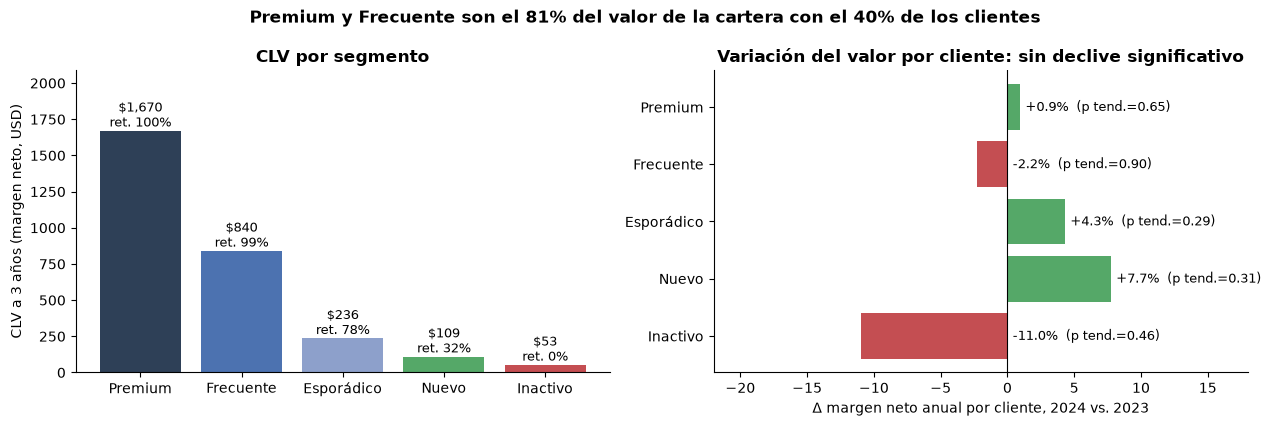

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]; b = ax.bar(clv_tab.index, clv_tab.CLV_3a, color=[PALETA[s] for s in clv_tab.index])
for r_, v, rr in zip(b, clv_tab.CLV_3a, clv_tab.retencion): ax.text(r_.get_x() + r_.get_width() / 2, v, f'${v:,.0f}\nret. {rr:.0%}', ha='center', va='bottom', fontsize=9)
ax.set_ylabel('CLV a 3 años (margen neto, USD)'); ax.set_title('CLV por segmento'); ax.set_ylim(0, clv_tab.CLV_3a.max() * 1.25)
ax = axes[1]
dd_ = dec.loc[ORDEN_SEG, 'Δ margen anual por cliente %']
ax.barh(dd_.index[::-1], dd_.values[::-1], color=['#C44E52' if v < 0 else '#55A868' for v in dd_.values[::-1]])
for k, (v, pv) in enumerate(zip(dd_.values[::-1], dec.loc[ORDEN_SEG, 'p_valor_tendencia'].values[::-1])):
    ax.text(max(v, 0) + 0.4, k, f'{v:+.1f}%  (p tend.={pv:.2f})', va='center', ha='left', fontsize=9)
ax.axvline(0, color='k', lw=.8); ax.set_xlim(-22, 18); ax.set_xlabel('Δ margen neto anual por cliente, 2024 vs. 2023')
ax.set_title('Variación del valor por cliente: sin declive significativo')
plt.suptitle(f"Premium y Frecuente son el {clv_tab.loc[['Premium','Frecuente'],'%_valor_cartera'].sum():.0f}% del valor de la cartera con el 40% de los clientes", fontweight='bold')
plt.tight_layout(); plt.savefig(FIG / 'a2_clv_segmentos.png', dpi=150); plt.show()

**Lectura del CLV**

| Segmento | CLV 3 años | Por qué |
|---|---|---|
| Premium | **$1.670** | 9,4 compras/año y retención del 100% |
| Frecuente | **$840** | 5,3 compras/año y retención del 99% |
| Esporádico | $236 | 1,7 compras/año y retención del 78% |
| Nuevo | $109 | Solo el 32% vuelve a comprar al año siguiente |
| Inactivo | $53 | Una sola compra, retención 0% |

- El **ticket promedio es igual en todos los segmentos (~$345)**: el valor de un cliente lo determinan su frecuencia y su retención, no cuánto gasta en cada compra.
- **Premium y Frecuente suman el 81% del valor de la cartera** con el 40% de los clientes registrados. El 20% de clientes de mayor margen concentra el 63% del margen neto, y el 96% de ese grupo es Premium o Frecuente.
- 508 clientes (6,7%) tienen margen neto acumulado **negativo** (restan $216K), por devoluciones de productos de bajo margen. En A3 se analizan como devolvedores recurrentes.
- El ranking de segmentos es el mismo con cualquier tasa de descuento (8–20%) y horizonte (2–5 años).

**¿Qué segmentos están en declive?**

Ningún segmento muestra una tendencia mensual estadísticamente significativa (todos los p ≥ 0,29): **no hay un colapso**. Sí hay señales de deterioro que hay que vigilar:
1. **Inactivo**: el margen anual por cliente cae 11% y el ticket 8% (el único segmento con un −8% como el que cita el caso). Pesa poco en valor (1,4% de la cartera).
2. **Frecuente**, el segmento más valioso por volumen: el margen por compra cae 3,7% (−2,3% de ticket) y el margen por cliente 2,2%. Es poco en porcentaje, pero sobre el 48% del valor de la cartera equivale a ≈ −$17K de margen por año.
3. **Captación de nuevos clientes**: la recompra al trimestre siguiente de las cohortes nuevas cae de **30,6% (2023-Q3) a 15,1% (2024-Q3)**. *Precaución:* las primeras cohortes incluyen clientes que ya existían antes de 2023 (censura por la izquierda), así que la comparación válida es entre las cohortes de 2024 (23,0% → 17,1% → 15,1%): **la tendencia a la baja se mantiene**. Además, el segmento Nuevo cae 11,7% en el segundo semestre de 2024.
4. **Esporádico**: el 47,6% de sus clientes no compra hace más de 180 días. Es el segmento de mayor valor *en riesgo* que se va a analizar en A3 (churn).

Conclusión: el valor de RetailVenture está **concentrado y es estable** en Premium y Frecuente; el deterioro está en **la incorporación y retención de clientes nuevos** y en la erosión del ticket de Frecuente.

## 3. Estacionalidad: picos, valles y tendencias

**Cuidado metodológico:** los meses no tienen la misma cantidad de días (febrero tiene 28), así que los índices estacionales se calculan sobre **venta promedio diaria** por mes. Que un mes quede arriba del promedio no alcanza para hablar de estacionalidad; se prueba de tres formas:
1. **Kruskal-Wallis**: ¿difiere la distribución de la venta diaria entre meses? Se aplica corrección de Bonferroni porque se hacen 10 pruebas (total, 6 categorías y 3 canales).
2. **Repetibilidad**: si la estacionalidad es real, el patrón mensual de 2023 debería repetirse en 2024 (correlación de los índices de los dos años).
3. **Tendencia**: pendiente OLS de las ventas mensuales.

In [15]:
dias = pd.date_range('2023-01-01', '2024-12-31')
def diaria(df): return df.groupby('fecha').monto_neto.sum().reindex(dias, fill_value=0)

def prueba_estacional(df, nombre):
    d = diaria(df)
    idx = d.groupby(d.index.month).mean(); idx = idx / idx.mean() * 100
    i23 = d[d.index.year == 2023].groupby(d[d.index.year == 2023].index.month).mean()
    i24 = d[d.index.year == 2024].groupby(d[d.index.year == 2024].index.month).mean()
    mens = df.groupby('mes').monto_neto.sum()
    fit = sm.OLS(mens.values, sm.add_constant(np.arange(len(mens)))).fit()
    return {'serie': nombre, 'mes_pico': int(idx.idxmax()), 'indice_pico': idx.max(), 'mes_valle': int(idx.idxmin()), 'indice_valle': idx.min(),
            'kruskal_p': stats.kruskal(*[g.values for _, g in d.groupby(d.index.month)]).pvalue,
            'corr_patron_2023_2024': np.corrcoef(i23, i24)[0, 1],
            'tendencia_%_mensual': fit.params[1] / mens.mean() * 100, 'tendencia_p': fit.pvalues[1]}, idx

filas, indices = [], {}
for nombre, df in [('TOTAL', ventas)] + [(c, g) for c, g in ventas.groupby('categoria')] + [(f'canal:{c}', g) for c, g in ventas.groupby('canal')]:
    f, idx = prueba_estacional(df, nombre); filas.append(f); indices[nombre] = idx
est = pd.DataFrame(filas).set_index('serie')
est['significativo_Bonferroni'] = est.kruskal_p < 0.05 / len(est)
est.to_csv(TAB / 'a2_estacionalidad_pruebas.csv')
est.round(3)

,mes_pico,indice_pico,mes_valle,indice_valle,kruskal_p,corr_patron_2023_2024,tendencia_%_mensual,tendencia_p,significativo_Bonferroni
serie,,,,,,,,,
TOTAL,3,103.387,1,95.464,0.630,-0.439,0.054,0.706,False
Alimentos_y_Bebidas,2,110.724,7,92.578,0.209,-0.006,-0.045,0.828,False
Belleza_y_Salud,7,107.552,5,94.408,0.521,-0.318,0.237,0.299,False
Deportes,2,110.439,4,90.817,0.046,0.330,-0.038,0.872,False
Electrónica,11,106.160,6,90.562,0.539,-0.061,0.032,0.898,False
Hogar_y_Deco,4,108.314,1,90.384,0.272,0.101,0.065,0.768,False
Ropa_y_Calzado,3,111.929,4,92.263,0.425,-0.181,0.231,0.408,False
canal:app_movil,9,112.387,8,88.021,0.582,0.177,0.009,0.972,False
canal:online,3,108.823,1,90.239,0.391,0.123,0.030,0.894,False


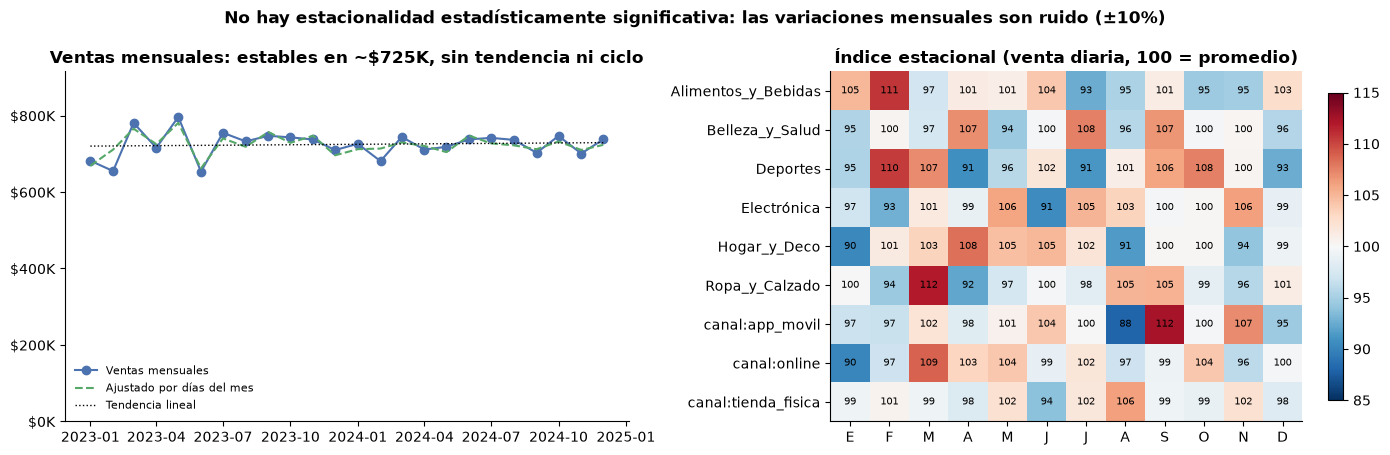

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={'width_ratios': [1.1, 1]})
ax = axes[0]
m_ = ventas.groupby('mes').agg(v=('monto_neto', 'sum'), n=('fecha', lambda s: s.dt.daysinmonth.iloc[0]))
x = m_.index.to_timestamp(); ax.plot(x, m_.v, marker='o', color='#4C72B0', label='Ventas mensuales')
ax.plot(x, m_.v / m_.n * 30.4, ls='--', color='#55A868', label='Ajustado por días del mes')
fit = np.polyfit(np.arange(len(m_)), m_.v, 1); ax.plot(x, np.polyval(fit, np.arange(len(m_))), color='k', lw=1, ls=':', label='Tendencia lineal')
ax.yaxis.set_major_formatter(usd); ax.set_ylim(0, m_.v.max() * 1.15); ax.legend(frameon=False, fontsize=8, loc='lower left')
ax.set_title('Ventas mensuales: estables en ~$725K, sin tendencia ni ciclo')
ax = axes[1]
hm = pd.DataFrame(indices).T.drop('TOTAL')
im = ax.imshow(hm.values, cmap='RdBu_r', vmin=85, vmax=115, aspect='auto')
ax.set_xticks(range(12), ['E', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D']); ax.set_yticks(range(len(hm)), hm.index)
for (r_, k), v in np.ndenumerate(hm.values): ax.text(k, r_, f'{v:.0f}', ha='center', va='center', fontsize=7)
plt.colorbar(im, ax=ax, fraction=.03); ax.set_title('Índice estacional (venta diaria, 100 = promedio)')
plt.suptitle('No hay estacionalidad estadísticamente significativa: las variaciones mensuales son ruido (±10%)', fontweight='bold')
plt.tight_layout(); plt.savefig(FIG / 'a2_estacionalidad.png', dpi=150); plt.show()

In [17]:
# Día de la semana y transacciones/ticket mensuales (¿el volumen o el ticket explican las variaciones?)
d = diaria(ventas)
print('Kruskal día de la semana p =', round(stats.kruskal(*[g.values for _, g in d.groupby(d.index.dayofweek)]).pvalue, 3))
print((d.groupby(d.index.dayofweek).mean() / d.mean() * 100).round(1).rename(dict(enumerate(['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom']))).to_dict())
mm = ventas.groupby('mes').agg(transacciones=('transaccion_id', 'size'), ticket=('monto_neto', 'mean'), desc=('descuento', 'mean'), mb=('margen_bruto', 'sum'), v=('monto_neto', 'sum'))
mm['mb_%'] = mm.mb / mm.v * 100
print('\nCoeficiente de variación mensual: transacciones {:.1%}, ticket {:.1%}, margen % {:.1%}'.format(*(mm[c].std() / mm[c].mean() for c in ['transacciones', 'ticket', 'mb_%'])))

Kruskal día de la semana p = 0.985
{'Lun': 101.0, 'Mar': 99.9, 'Mié': 99.6, 'Jue': 101.0, 'Vie': 100.9, 'Sáb': 99.4, 'Dom': 98.2}

Coeficiente de variación mensual: transacciones 3.0%, ticket 3.7%, margen % 1.9%


**Lectura**

**No hay estacionalidad estadísticamente significativa** en el total, en ninguna categoría ni en ningún canal:
- Kruskal-Wallis: p = 0,63 en el total. La única p < 0,05 es la de Deportes (0,046), y deja de ser significativa al corregir por 10 pruebas (umbral de Bonferroni: 0,005).
- **El patrón no se repite**: la correlación entre los índices mensuales de 2023 y 2024 es −0,44 en el total. Si febrero o marzo fueran estacionales de verdad, lo serían en los dos años.
- **No hay tendencia**: pendiente de +0,05% mensual (p = 0,71). Las ventas son estables en ~$725K por mes, con un coeficiente de variación del 3% en transacciones y del 3,7% en ticket.
- El aparente valle de febrero (−8%) **desaparece al ajustar por días del mes** (índice diario 98,5). Es un efecto de calendario, no de demanda.
- El día de la semana tampoco influye (p = 0,99).

Los "picos" y "valles" de la tabla (por ejemplo, Ropa en marzo con 112, o app móvil en agosto con 88) son **ruido muestral**, y presentarlos como estacionalidad sería un error metodológico.

**Implicaciones de negocio:**
1. La presión sobre los márgenes es **estructural, no cíclica**: no se explica por una temporada baja ni se va a corregir sola.
2. No hay picos de demanda que justifiquen descuentos *de temporada*. Los descuentos actuales no se concentran en ningún momento del año: están repartidos de forma pareja.
3. Para inventario y personal se puede planificar con una demanda plana. Para el relato: el dataset es sintético y no reproduce ciclos típicos del retail venezolano (diciembre, regreso a clases), y conviene decirlo si preguntan.

## 4. Efecto real de los descuentos sobre el margen

La pregunta es causal: **¿el descuento *provoca* más volumen?** Comparar sin más las transacciones con y sin descuento puede engañar, porque el descuento no se asigna al azar: puede concentrarse en ciertos productos, canales o clientes. Por eso se hacen tres análisis:
1. **Descriptivo** por tramo de descuento.
2. **Efectos fijos de producto**: compara el *mismo producto* vendido con y sin descuento, controlando además por segmento y canal. Así se elimina el sesgo de que los productos caros o baratos tengan descuentos distintos.
3. **Efectos fijos de cliente** (*within-customer*): ¿un mismo cliente vuelve antes o gasta más tras una compra con descuento? Mide si el descuento genera frecuencia, y no solo unidades en la misma compra.

Por último se compara el volumen observado con el **volumen de equilibrio**: el aumento de unidades que haría falta para que el margen total no cayera.

In [18]:
ventas['tramo_desc'] = pd.cut(ventas.descuento, [-.001, 0, .05, .10, .15, .20, .40], labels=['0%', '0–5%', '5–10%', '10–15%', '15–20%', '>20%'])
tr = ventas.groupby('tramo_desc', observed=True).agg(transacciones=('transaccion_id', 'size'), desc_prom=('descuento', 'mean'),
        unidades_por_trx=('cantidad', 'mean'), ticket=('monto_neto', 'mean'), margen_bruto_trx=('margen_bruto', 'mean'),
        mb_pct=('margen_bruto_pct', 'mean'), tasa_dev=('flag_devuelta', 'mean'), trx_margen_negativo=('margen_bruto', lambda s: (s < 0).mean()))
tr['%_trx'] = tr.transacciones / tr.transacciones.sum() * 100
tr.to_csv(TAB / 'a2_descuentos_tramos.csv')
tr.style.format({'desc_prom': '{:.1%}', 'unidades_por_trx': '{:.3f}', 'ticket': '${:,.0f}', 'margen_bruto_trx': '${:,.1f}', 'mb_pct': '{:.1f}%',
                 'tasa_dev': '{:.1%}', 'trx_margen_negativo': '{:.1%}', '%_trx': '{:.1f}%'})

,transacciones,desc_prom,unidades_por_trx,ticket,margen_bruto_trx,mb_pct,tasa_dev,trx_margen_negativo,%_trx
tramo_desc,,,,,,,,,
0%,14660,0.0%,1.782,$365,$105.3,34.3%,13.3%,0.0%,29.3%
0–5%,16922,2.4%,1.781,$354,$96.4,32.8%,13.3%,0.0%,33.8%
5–10%,8903,7.2%,1.778,$339,$77.8,29.3%,13.9%,0.1%,17.8%
10–15%,4269,12.4%,1.780,$327,$61.4,25.0%,13.4%,2.4%,8.5%
15–20%,3368,17.4%,1.803,$318,$42.8,20.0%,13.6%,8.0%,6.7%
>20%,1878,22.9%,1.791,$292,$20.1,14.2%,13.4%,17.8%,3.8%


In [19]:
# (2) Efecto del descuento sobre unidades, controlando por producto (+ segmento y canal)
r1 = smf.ols('cantidad ~ descuento + C(producto_id)', data=ventas).fit(cov_type='cluster', cov_kwds={'groups': ventas.producto_id})
r2 = smf.ols('cantidad ~ descuento + C(producto_id) + C(segmento) + C(canal) + C(mes_str)', data=ventas.assign(mes_str=ventas.mes.astype(str))).fit(cov_type='cluster', cov_kwds={'groups': ventas.producto_id})
base_q = ventas.cantidad.mean()
reg = pd.DataFrame({
    'modelo': ['EF producto', 'EF producto + segmento + canal + mes'],
    'efecto_+10pp_desc_en_unidades': [r.params['descuento'] * .10 for r in (r1, r2)],
    'efecto_%_sobre_media': [r.params['descuento'] * .10 / base_q * 100 for r in (r1, r2)],
    'IC95_inf_%': [r.conf_int().loc['descuento', 0] * .10 / base_q * 100 for r in (r1, r2)],
    'IC95_sup_%': [r.conf_int().loc['descuento', 1] * .10 / base_q * 100 for r in (r1, r2)],
    'p_valor': [r.pvalues['descuento'] for r in (r1, r2)]})
reg.round(4)

,modelo,efecto_+10pp_desc_en_unidades,efecto_%_sobre_media,IC95_inf_%,IC95_sup_%,p_valor
0,EF producto,0.0060,0.3347,-0.4942,1.1637,0.4287
1,EF producto + segmento + canal + mes,0.0038,0.2136,-0.6673,1.0944,0.6346


In [20]:
# (3) Within-customer: tras una compra con descuento, ¿el cliente vuelve antes o gasta más en la siguiente?
v = ventas.sort_values(['cliente_id', 'fecha']).copy()
v['dias_a_siguiente'] = v.groupby('cliente_id').fecha.shift(-1).sub(v.fecha).dt.days
v['monto_siguiente'] = v.groupby('cliente_id').monto_neto.shift(-1)
w = v.dropna(subset=['dias_a_siguiente']).copy()
w = w[w.groupby('cliente_id').cliente_id.transform('size') >= 2]          # clientes con variación interna
def within(df, y, x='descuento', g='cliente_id'):
    dm = df[[y, x]] - df.groupby(g)[[y, x]].transform('mean')            # transformación within (EF de cliente)
    fit = sm.OLS(dm[y], dm[[x]]).fit(cov_type='cluster', cov_kwds={'groups': df[g]})
    return fit.params[x] * .10, fit.conf_int().loc[x].values * .10, fit.pvalues[x]
for y in ['dias_a_siguiente', 'monto_siguiente']:
    b, ci, p = within(w, y)
    print(f'{y}: +10 pp de descuento → {b:+.2f} (IC95 {ci[0]:+.2f} a {ci[1]:+.2f}), p = {p:.3f}   | media = {w[y].mean():.1f}')

dias_a_siguiente: +10 pp de descuento → -0.52 (IC95 -1.59 a +0.56), p = 0.345   | media = 63.6
monto_siguiente: +10 pp de descuento → +7.21 (IC95 -1.21 a +15.63), p = 0.093   | media = 348.3


In [21]:
# (4) Margen extensivo: ¿los meses / clientes con más descuento tienen MÁS transacciones?
mm_ = ventas.groupby('mes').agg(desc=('descuento', 'mean'), trx=('transaccion_id', 'size'))
r_, p_ = stats.pearsonr(mm_.desc, mm_.trx)
print(f'Meses: correlación descuento promedio vs. n.º de transacciones r = {r_:+.2f} (p = {p_:.2f}, n = 24)')
cd = ventas.groupby('cliente_id').agg(desc=('descuento', 'mean'), trx=('transaccion_id', 'size'), seg=('segmento', 'first'))
cd = cd[cd.trx >= 2]
fit_ = smf.ols('trx ~ desc + C(seg)', data=cd).fit(cov_type='HC1')
print(f"Clientes: +10 pp de descuento promedio → {fit_.params['desc']*.1:+.2f} compras (p = {fit_.pvalues['desc']:.2f}), controlando por segmento")

Meses: correlación descuento promedio vs. n.º de transacciones r = +0.02 (p = 0.92, n = 24)
Clientes: +10 pp de descuento promedio → -0.05 compras (p = 0.53), controlando por segmento


In [22]:
# Volumen de equilibrio: aumento de unidades necesario para que un descuento d no reduzca el margen en USD
#   margen unitario sin descuento = P·m ; con descuento = P·(m − d)  →  volumen necesario = m / (m − d)
cat_m = ventas.assign(ml=(ventas.ingreso_bruto - ventas.costo_total) / ventas.ingreso_bruto).groupby('categoria').ml.mean()
be = pd.DataFrame({f'd={d:.0%}': np.where(cat_m > d, (cat_m / (cat_m - d) - 1) * 100, np.inf) for d in (.05, .10, .15, .20)}, index=cat_m.index)
be.insert(0, 'margen_a_precio_lista_%', cat_m * 100)
print('Aumento de volumen (%) necesario para compensar el descuento — inf = el descuento supera el margen:')
display(be.round(0))
print(f"Aumento de volumen observado con +10 pp de descuento: {reg.iloc[1]['efecto_%_sobre_media']:+.1f}% (no significativo)")

Aumento de volumen (%) necesario para compensar el descuento — inf = el descuento supera el margen:


,margen_a_precio_lista_%,d=5%,d=10%,d=15%,d=20%
categoria,,,,,
Alimentos_y_Bebidas,27.0,22.0,57.0,120.0,269.0
Belleza_y_Salud,44.0,13.0,29.0,51.0,82.0
Deportes,39.0,15.0,35.0,64.0,108.0
Electrónica,19.0,37.0,117.0,421.0,inf
Hogar_y_Deco,34.0,17.0,41.0,77.0,139.0
Ropa_y_Calzado,43.0,13.0,30.0,54.0,87.0


Aumento de volumen observado con +10 pp de descuento: +0.2% (no significativo)


In [23]:
# Costo total de los descuentos y escenario contrafactual
desc_total = ventas.descuento_monto.sum()
print(f'Descuentos concedidos en 24 meses: ${desc_total:,.0f} = {desc_total / ventas.margen_bruto.sum():.1%} del margen bruto obtenido')
print(f'Como el volumen no responde, cada USD de descuento es ~1 USD de margen perdido.')
by = ventas.groupby('categoria').agg(desc=('descuento_monto', 'sum'), mb=('margen_bruto', 'sum'))
by['desc_%_margen'] = by.desc / by.mb * 100; display(by.round(0))
neg = ventas[ventas.margen_bruto < 0]
print(f'Transacciones vendidas por debajo del costo: {len(neg):,} ({len(neg)/len(ventas):.1%}); pérdida: ${-neg.margen_bruto.sum():,.0f}')
print(neg.categoria.value_counts().head(3).to_dict())

Descuentos concedidos en 24 meses: $967,701 = 22.5% del margen bruto obtenido
Como el volumen no responde, cada USD de descuento es ~1 USD de margen perdido.


,desc,mb,desc_%_margen
categoria,,,
Alimentos_y_Bebidas,22335.0,94268.0,24.0
Belleza_y_Salud,40772.0,309503.0,13.0
Deportes,148980.0,907214.0,16.0
Electrónica,431110.0,1049301.0,41.0
Hogar_y_Deco,241976.0,1353038.0,18.0
Ropa_y_Calzado,82527.0,597005.0,14.0


Transacciones vendidas por debajo del costo: 711 (1.4%); pérdida: $30,181
{'Electrónica': 633, 'Alimentos_y_Bebidas': 71, 'Hogar_y_Deco': 6}


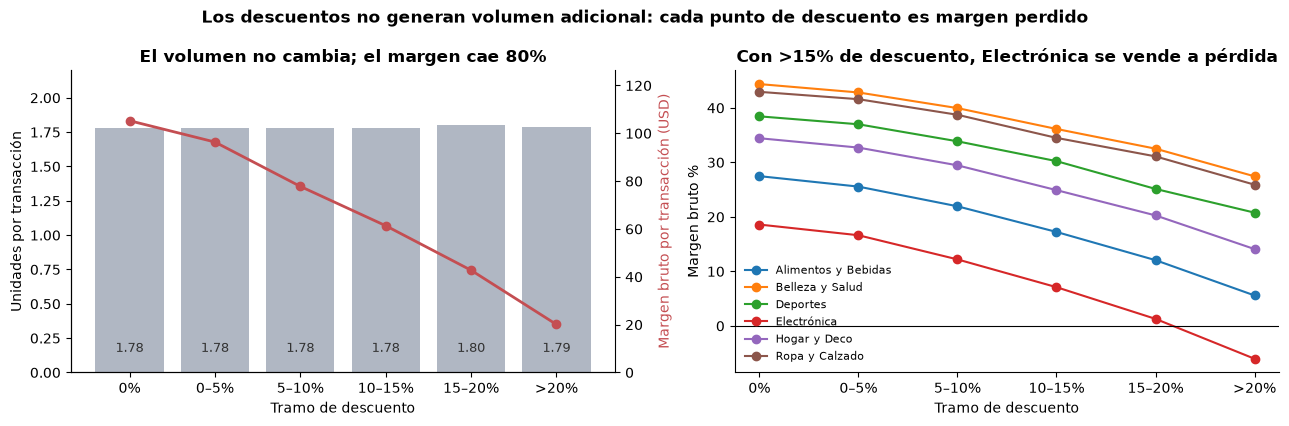

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
ax.bar(tr.index.astype(str), tr.unidades_por_trx, color='#B0B7C3'); ax.set_ylim(0, 2.2); ax.set_ylabel('Unidades por transacción')
for k, v in enumerate(tr.unidades_por_trx): ax.text(k, .15, f'{v:.2f}', ha='center', fontsize=9, color='#333')
ax2 = ax.twinx(); ax2.plot(tr.index.astype(str), tr.margen_bruto_trx, color='#C44E52', marker='o', lw=2)
ax2.set_ylabel('Margen bruto por transacción (USD)', color='#C44E52'); ax2.set_ylim(0, tr.margen_bruto_trx.max() * 1.2); ax2.spines['right'].set_visible(True)
ax.set_xlabel('Tramo de descuento'); ax.set_title('El volumen no cambia; el margen cae 80%')
ax = axes[1]
for cat in be.index:
    s = ventas[ventas.categoria == cat].groupby('tramo_desc', observed=True).margen_bruto_pct.mean()
    ax.plot(s.index.astype(str), s.values, marker='o', label=cat.replace('_', ' '))
ax.axhline(0, color='k', lw=.8); ax.set_ylabel('Margen bruto %'); ax.set_xlabel('Tramo de descuento'); ax.legend(frameon=False, fontsize=8)
ax.set_title('Con >15% de descuento, Electrónica se vende a pérdida')
plt.suptitle('Los descuentos no generan volumen adicional: cada punto de descuento es margen perdido', fontweight='bold')
plt.tight_layout(); plt.savefig(FIG / 'a2_descuentos.png', dpi=150); plt.show()

**Lectura: los descuentos NO generan volumen suficiente; de hecho, no generan volumen.**

| Prueba | Resultado |
|---|---|
| Descriptivo | Las unidades por transacción son iguales en todos los tramos (1,78 a 1,80), mientras el margen por transacción cae de $105 a $20 (−81%). |
| Efectos fijos de producto (+ segmento, canal y mes) | +10 pp de descuento → **+0,2% de unidades** (IC95: −0,7% a +1,1%; p = 0,63). Es estadísticamente cero. |
| Efectos fijos de cliente | Tras una compra con descuento, el cliente no vuelve antes (−0,5 días, p = 0,35) ni gasta significativamente más en la siguiente compra (p = 0,09). |
| Margen extensivo | Los meses con más descuento no tienen más transacciones (r = +0,02; p = 0,92), y los clientes con más descuento promedio no compran más veces (p = 0,53). |
| Volumen de equilibrio | Para compensar un 10% de descuento, Electrónica necesitaría **+117% de volumen** y Hogar +41%. El volumen observado es +0,2%. |

**Impacto económico:**
- Se concedieron **$968K en descuentos en 24 meses, el 22,5% del margen bruto obtenido**. Como el volumen no responde, cada dólar de descuento es prácticamente un dólar de margen perdido.
- En Electrónica, los descuentos equivalen al **41% de su margen bruto**. Con descuentos mayores al 15% se vende *por debajo del costo*: 711 transacciones a pérdida, 633 de ellas de Electrónica.

**Causalidad y límites:** el diseño con efectos fijos compara el mismo producto, o el mismo cliente, con y sin descuento, lo que elimina los sesgos de composición más obvios. Aun así, es evidencia **observacional**. No vemos a quienes *no* compraron (puede haber ventas que el descuento sí "rescató"), aunque el análisis mensual y por cliente no muestra ese efecto. La forma de confirmarlo es un **experimento A/B**: reducir el descuento online en un grupo de control durante 8 semanas. En cualquier caso, la evidencia apunta a que **los descuentos actuales son una transferencia de margen al cliente sin retorno en volumen**.

## Resumen ejecutivo de A2

1. **El problema de rentabilidad está en el *mix* y en los descuentos, no en los clientes.** Electrónica es el 44% de las ventas pero solo el 16% del margen neto (6,3% de margen neto, 17,7% de devoluciones). Hogar y Deco, Deportes y Belleza y Salud generan el 69% del margen neto con el 45% de las ventas.
2. **El canal online pierde 3,2 pp de margen porque descuenta el doble** (7,7% vs. 3,7%), con la misma mezcla de productos. Igualar su descuento al de la tienda vale ≈ $139K de margen por año.
3. **Los descuentos no generan volumen** (efecto de +0,2%, no significativo, con cuatro pruebas distintas). Costaron $968K, el 22,5% del margen bruto. Con más de 15% de descuento, Electrónica se vende a pérdida.
4. **CLV:** Premium $1.670 y Frecuente $840 representan el 81% del valor de la cartera. No hay declive significativo en el agregado, pero hay señales tempranas: cae la recompra de las cohortes nuevas (de 23% a 15% en 2024), el margen por compra de Frecuente baja 3,7% y el de Inactivo 11%.
5. **No hay estacionalidad ni tendencia**: las ventas son planas en ~$725K por mes. La caída de márgenes es estructural y no se va a corregir sola.

→ **Insumos para A3:** el 47,6% de los Esporádicos lleva más de 180 días sin comprar (riesgo de churn); hay devolvedores recurrentes (508 clientes con margen negativo); las tasas de devolución de Ropa (21,8%) y Electrónica (17,7%) son anómalas.